In [1]:
%config InlineBackend.figure_format = 'retina'

import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display

from cognitive_maps_in_llms.analysis import RunResults, plot_mosaic_series
from cognitive_maps_in_llms.analysis.style import PAPER_MOSAIC_STYLE


In [2]:
REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'src' / 'cognitive_maps_in_llms').is_dir()
)

# SET INPUT AND OUTPUT PATHS

# ------------------------------------------------------------------------------
RESULTS_ROOT = REPO_ROOT / 'results/final_run_2026-09-30'
FIGURES_DIR = REPO_ROOT / 'figures/generated/main_text/figure_5'
SAVE_FIGURES = True
# ------------------------------------------------------------------------------

if SAVE_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RESULTS = RunResults(results_root=RESULTS_ROOT)

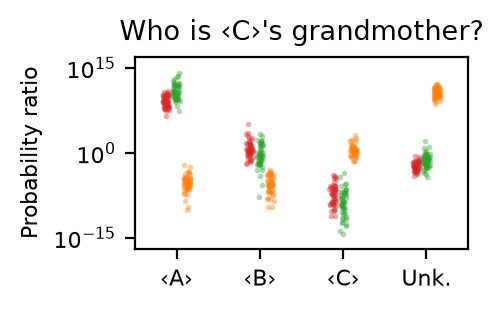

In [3]:
# FIGURE 5A

MODEL_PRESET  = 'gemma-27b'
PROMPT_PRESET = 'ABC_family_tree_who_is'
EXPERIMENT = 'exp_5a_bottleneck'
QUERY = 'C --grandmother--> ?'

control = RESULTS.load_series(
    model_preset = MODEL_PRESET,
    prompt_preset = PROMPT_PRESET,
    experiment = EXPERIMENT,
    query = QUERY,
    condition = 'CTRL'
)
keys_first = RESULTS.load_series(
    model_preset = MODEL_PRESET,
    prompt_preset = PROMPT_PRESET,
    experiment = EXPERIMENT,
    query = QUERY,
    condition = 'K_THEN_V'
)
keys_only = RESULTS.load_series(
    model_preset = MODEL_PRESET,
    prompt_preset = PROMPT_PRESET,
    experiment = EXPERIMENT,
    query = QUERY,
    condition = 'K_ONLY'
)
values_first = RESULTS.load_series(
    model_preset = MODEL_PRESET,
    prompt_preset = PROMPT_PRESET,
    experiment = EXPERIMENT,
    query = QUERY,
    condition = 'V_THEN_K'
)

plot = plot_mosaic_series(
    {"Control": control, "Keys-first": keys_first, "Values-first": values_first},
    value_kind = "probability_ratio",
    colors = ("tab:red", "tab:green", "tab:orange"),
    jitter = 0.04,
    title = "Who is ‹C›'s grandmother?"
)
plot.ax.set_ylim((1e-17, 1e17))

display(plot.fig)
if SAVE_FIGURES:
    plot.save(FIGURES_DIR / 'bottlenecks.svg')
plt.close(plot.fig)

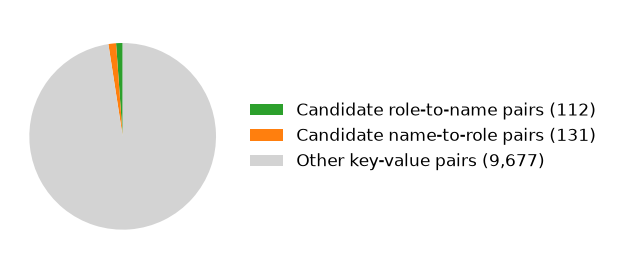

In [4]:
# FIGURE 5B, SPARSE KV COUNTS

MODEL_PRESET = 'gemma-27b'
PROMPT_PRESET = 'ABC_family_tree_who_is'

results_path = RESULTS_ROOT / MODEL_PRESET / PROMPT_PRESET / 'exp_5b_sparse_mosaic' / 'results.ndjson'
with results_path.open() as file:
    info = next(record['trial_info'] for record in map(json.loads, file)
                if record['trial_key']['condition'] == 'FIDELITY_95_SITES_X2')
trajectory = RESULTS.load_erasure_trajectory(
    model_preset=MODEL_PRESET, prompt_preset=PROMPT_PRESET,
)
counts = [info['n_keys'], info['n_values']]
counts.append(trajectory.key_erasure_round_tli.size - sum(counts))
labels = ['Candidate role-to-name pairs', 'Candidate name-to-role pairs', 'Other key-value pairs']

with mpl.rc_context(PAPER_MOSAIC_STYLE.rc_params()):
    fig, ax = plt.subplots(figsize=(4.3, 1.25), layout='constrained')
    wedges, _ = ax.pie(counts, colors=['tab:green', 'tab:orange', 'lightgrey'], startangle=90)
    ax.set_xlim(-1.1, 3.5)
    ax.legend(wedges, [f'{label} ({count:,})' for label, count in zip(labels, counts)],
              loc='center left', bbox_to_anchor=(0.5, 0.5),
              frameon=False, fontsize=PAPER_MOSAIC_STYLE.legend_font_size)

    display(fig)
    if SAVE_FIGURES:
        output_path = FIGURES_DIR / f'sparse_kv_pie_{MODEL_PRESET}_{PROMPT_PRESET}.svg'
        fig.savefig(output_path, bbox_inches='tight')
    plt.close(fig)

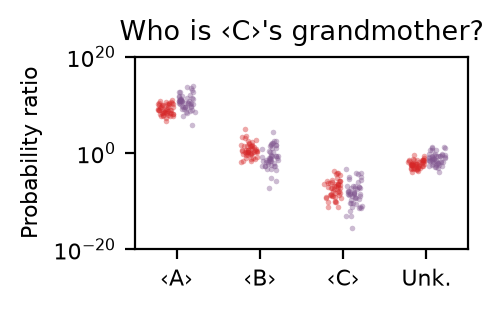

In [5]:
# FIGURE 5B

MODEL_PRESET  = 'gemma-27b'

# ----------------------------------------------
PROMPT_PRESET = 'ABC_family_tree_who_is'
EXPERIMENT = 'exp_5b_sparse_mosaic'
QUERY = 'C --grandmother--> ?'

control = RESULTS.load_series(
    model_preset = MODEL_PRESET,
    prompt_preset = PROMPT_PRESET,
    experiment = EXPERIMENT,
    query = QUERY,
    condition = 'REPLACE_ALL'
)
sparse_mosaic = RESULTS.load_series(
    model_preset = MODEL_PRESET,
    prompt_preset = PROMPT_PRESET,
    experiment = EXPERIMENT,
    query = QUERY,
    condition = 'FIDELITY_95_SITES_X2'
)

plot = plot_mosaic_series(
    {"Control": control, "Sparse KV subset": sparse_mosaic},
    value_kind = "probability_ratio",
    title = "Who is ‹C›'s grandmother?"
)
# plot.ax.set_ylim((1e-17, 1e17))

display(plot.fig)
if SAVE_FIGURES:
    plot.save(FIGURES_DIR / 'sparse_mosaic.svg')
plt.close(plot.fig)

In [6]:
# FIGURE 5C

MODEL_PRESET  = 'gemma-27b'
PROMPT_PRESET = 'ABC_family_tree_who_is'
EXPERIMENT = 'exp_5c_editing'

def plot_figure_5c_query(query: str, title: str, filename: str):
    control = RESULTS.load_series(
        model_preset=MODEL_PRESET,
        prompt_preset=PROMPT_PRESET,
        experiment=EXPERIMENT,
        query=query,
        condition = 'FIDELITY_95_SITES_X2',
        editing_locs = 'NONE'
    )
    mosaic = RESULTS.load_series(
        model_preset=MODEL_PRESET,
        prompt_preset=PROMPT_PRESET,
        experiment=EXPERIMENT,
        query=query,
        condition = 'FIDELITY_95_SITES_X2',
        editing_locs = 'A_VALUES'
    )

    plot = plot_mosaic_series(
        {'Control': control, 'Mosaic': mosaic},
        value_kind='probability_ratio',
        title=title,
        symbols = ('A', 'B', 'C', 'D', 'U')
    )
    if SAVE_FIGURES:
        plot.save(FIGURES_DIR / filename)
    return plot


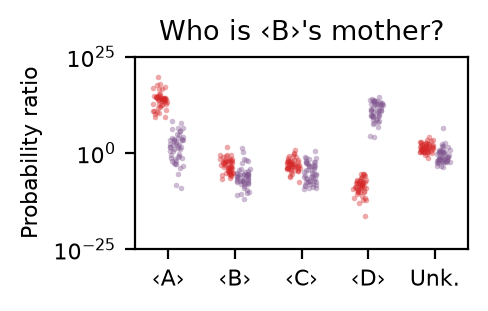

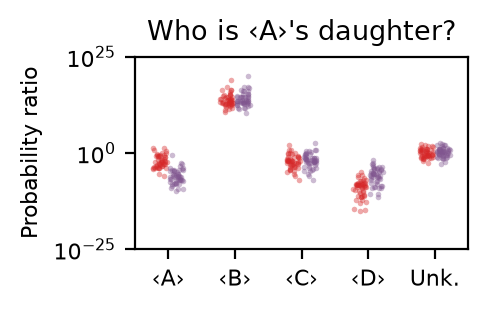

In [7]:
FIGURE_SPECS = (
    ('B --mother--> ?', "Who is ‹B›'s mother?", 'editing_who_is_Bs_mother.svg'),
    ('A --daughter--> ?', "Who is ‹A›'s daughter?", 'editing_who_is_As_daughter.svg'),
)

for query, title, filename in FIGURE_SPECS:
    plot = plot_figure_5c_query(query, title, filename)
    display(plot.fig)
    plt.close(plot.fig)